# Kafka → Spark → Cassandra replay performance

Measure the deployed XGBoost pipeline at its fixed 0.5 threshold. Notebook 06 measures local model calls. Here the timed CLI publishes and drains Kafka first, then launches a fresh Spark process. Spark loads the deployed model, initializes its workers and Kafka query, scores the rows, and waits for the Cassandra write helper. The larger workload repeats the first 1,000 rows of the fixed seed-42 test CSV three times at a target of 200 events/s. The 32-row fixture checks instrumentation and prediction parity.

## Check workload, environment and clock

Load the saved launch, producer, Spark, and Docker metadata. Verify that each launch, producer, and Spark timestamp uses the same Linux boot and time namespace. The producer records in Python immediately before Py4J calls the Java Kafka client. Spark records after the Cassandra driver confirms the last write in a micro-batch. All timestamps are monotonic nanoseconds with a shared origin.

In [1]:
%matplotlib inline
import gzip
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

root = Path.cwd().resolve()
if root.name == "notebooks":
    root = root.parent
figures = root / "figures"
saved = json.loads((figures / "streaming_performance_summary.json").read_text())
runs = saved["runs"]
environment = saved["environment"]
spark = runs[0]["timing"]["spark"]
for run in runs:
    timing = run["timing"]
    clock = timing["spark"]["clock"]
    assert clock == timing["producer"]["clock"] == timing["launch"]["clock"]
    assert (clock["clock"], clock["units"]) == ("CLOCK_MONOTONIC", "nanoseconds")
    assert timing["spark"]["model_sha256"] == spark["model_sha256"]
    assert timing["spark"]["threshold"] == 0.5

specification = {
    "CPU": environment["cpu"],
    "WSL": f"{environment['wsl_logical_cpus']} logical CPUs · {environment['wsl_memory_kib'] / 2**20:.2f} GiB",
    "Kernel": environment["kernel"],
    "Docker": f"{environment['docker_version']} · {environment['docker_logical_cpus']} CPUs · {environment['docker_memory_bytes'] / 2**30:.2f} GiB",
    "Spark": f"{spark['spark_version']} · {spark['spark_master']} · Python {spark['python_version']}",
    "Spark cgroup": f"cpu.max = {spark['cpu_max']} · memory.max = {spark['memory_max']}",
    "Model": f"xgboost_final.ubj (export {spark['xgboost_export']}, runtime {spark['xgboost_runtime']}) · cutoff {spark['threshold']}",
    "Model SHA-256": spark["model_sha256"],
    "Kafka": f"{environment['kafka']} · {environment['kafka_partitions']} partitions · producer acks=all",
    "Spark trigger": f"{spark['trigger']} · {spark['starting_offsets']} offsets · {spark['max_offsets_per_trigger']:,} max offsets per trigger",
    "Cassandra": f"{environment['cassandra']} · consistency code {spark['cassandra_consistency']} (LOCAL_ONE) · {spark['cassandra_write_concurrency']} concurrent writes",
    "Dashboard quota": f"{environment['service_limits']['dashboard']['cpu_limit']:g} CPU · {environment['service_limits']['dashboard']['memory_limit_bytes'] / 2**20:g} MiB",
}
with pd.option_context("display.max_colwidth", 100):
    display(pd.Series(specification, name="Recorded setting").to_frame())
display(Markdown(
    f"**Interpretation.** Docker exposed {environment['docker_logical_cpus']} logical CPUs and "
    f"{environment['docker_memory_bytes'] / 2**30:.2f} GiB to the stack. Spark used two local execution threads. "
    "Its container had no separate cgroup CPU quota or memory cap. Kafka and Cassandra also had no explicit "
    "CPU or memory limit in Docker; Cassandra used the configured 1 GiB Java heap maximum."
))

,Recorded setting
CPU,AMD Ryzen 9 7940HS w/ Radeon 780M Graphics
WSL,6 logical CPUs · 9.71 GiB
Kernel,6.18.58.1-microsoft-standard-WSL2
Docker,29.4.0 · 6 CPUs · 9.71 GiB
Spark,3.5.7 · local[2] · Python 3.10.22
Spark cgroup,cpu.max = max 100000 · memory.max = max
Model,"xgboost_final.ubj (export 3.4.1, runtime 3.2.0) · cutoff 0.5"
Model SHA-256,ea40536649ee763c9a6ae1adbf18ed1cd4edc5ba2c5f7c2cedb7a09ba9be77fd
Kafka,apache/kafka:3.9.1 · 2 partitions · producer acks=all
Spark trigger,"availableNow · earliest offsets · 1,000 max offsets per trigger"


**Interpretation.** Docker exposed 6 logical CPUs and 9.71 GiB to the stack. Spark used two local execution threads. Its container had no separate cgroup CPU quota or memory cap. Kafka and Cassandra also had no explicit CPU or memory limit in Docker; Cassandra used the configured 1 GiB Java heap maximum.

## Audit the event evidence

Join the raw send and acknowledgement records by run ID and event ID, and cross-check the independent Cassandra read-back. Count missing IDs against each run’s expected range. Count duplicate IDs within the send, acknowledgement, and read-back streams. This measures duplicates visible in the evidence; Cassandra’s primary key coalesces repeated writes for the same key.

In [2]:
with gzip.open(figures / "streaming_performance_events.jsonl.gz", "rt") as source:
    evidence = pd.DataFrame(json.loads(line) for line in source)
for column in ("send_ns", "ack_ns", "batch_start_ns", "batch_id"):
    evidence[column] = evidence[column].astype("Int64")

keys = ["run_id", "event_id"]
confirmed_by_run = {}
checks = []
for run in runs:
    rows = evidence[evidence["run_id"].eq(run["run_id"])]
    groups = {kind: rows[rows["kind"].eq(kind)] for kind in ("send", "ack", "stored")}
    ids = {kind: set(group["event_id"]) for kind, group in groups.items()}
    expected = set(range(run["rows"]))
    confirmed_ids = expected.intersection(*ids.values())
    missing = sorted(expected - confirmed_ids)
    duplicates = {kind: sorted(group.loc[group["event_id"].duplicated(), "event_id"].unique())
                  for kind, group in groups.items()}
    assert duplicates == run["duplicate_event_ids"]
    assert missing == run["missing_event_ids"]
    assert len(ids["stored"]) == run["stored_unique_events"]
    assert not missing and not any(duplicates.values())
    assert all(values == expected for values in ids.values())
    confirmed = groups["send"][keys + ["send_ns"]].merge(
        groups["ack"][keys + ["batch_id", "batch_start_ns", "ack_ns"]], on=keys, validate="one_to_one",
    )
    confirmed["latency_ms"] = (confirmed["ack_ns"] - confirmed["send_ns"]) / 1e6
    confirmed_by_run[run["run_id"]] = confirmed
    checks.append({"Run": run["run_id"], "Expected": run["rows"], "Stored unique": len(ids["stored"]),
                   "Missing": len(missing), "Duplicates (send / ack / stored)": " / ".join(map(str, map(len, duplicates.values()))),
                   "Micro-batches": confirmed["batch_id"].nunique()})

display(pd.DataFrame(checks))
display(confirmed_by_run[runs[0]["run_id"]][keys + ["send_ns", "ack_ns"]].head(3))
display(Markdown(
    f"**Interpretation.** All {sum(row['Stored unique'] for row in checks):,} expected events were confirmed in Cassandra. "
    "Every measured replay fit in one micro-batch. The sample timestamps show distinct send times and "
    "one shared acknowledgement after the batch write completed. The 32-row fixture also matched all "
    "reference classes; the CLI checked the first write and retry within its 1e-7 score tolerance."
))

,Run,Expected,Stored unique,Missing,Duplicates (send / ack / stored),Micro-batches
0,run.XSIuwfM4,32,32,0,0 / 0 / 0,1
1,run.KNuQZucQ,1000,1000,0,0 / 0 / 0,1
2,run.mfFRxgpV,1000,1000,0,0 / 0 / 0,1
3,run.19KYjKON,1000,1000,0,0 / 0 / 0,1


,run_id,event_id,send_ns,ack_ns
0,run.XSIuwfM4,0,13356112471109,13366174963850
1,run.XSIuwfM4,1,13356124284181,13366174963850
2,run.XSIuwfM4,2,13356124632225,13366174963850


**Interpretation.** All 3,032 expected events were confirmed in Cassandra. Every measured replay fit in one micro-batch. The sample timestamps show distinct send times and one shared acknowledgement after the batch write completed. The 32-row fixture also matched all reference classes; the CLI checked the first write and retry within its 1e-7 score tolerance.

## Calculate per-run latency, throughput and fresh Spark startup

Latency is elapsed time from a row’s send call to its shared batch acknowledgement. P95 uses linear interpolation. Throughput is unique confirmed events divided by elapsed time from first send to last acknowledgement. Actual send rate uses send intervals from first to last send. The fresh Spark startup interval runs from the host launching its Spark container to the first nonempty micro-batch callback. The query-start column ends earlier, when `query.start()` returned.

In [3]:
report = []
for run in runs:
    events = confirmed_by_run[run["run_id"]]
    first_send, last_send = events["send_ns"].min(), events["send_ns"].max()
    last_ack = events["ack_ns"].max()
    elapsed = (last_ack - first_send) / 1e9
    rates = {
        "actual_send_eps": (len(events) - 1) * 1e9 / (last_send - first_send),
        "throughput_eps": len(events) / elapsed,
        "median_ms": float(events["latency_ms"].median()),
        "p95_ms": float(events["latency_ms"].quantile(0.95)),
    }
    for key, value in rates.items():
        assert np.isclose(value, run[key], rtol=0, atol=1e-9)
    launch = run["timing"]["launch"]["spark_launch_ns"]
    assert last_send <= run["timing"]["producer"]["publish_complete_ns"] <= launch
    cold = (events["batch_start_ns"].min() - launch) / 1e9
    assert np.isclose(cold, run["spark_launch_to_first_batch_s"], rtol=0, atol=1e-9)
    report.append({
        "Workload": run["workload"], "Run": run["run_id"], "Confirmed": len(events),
        "Actual send (events/s)": rates["actual_send_eps"], "Median (s)": rates["median_ms"] / 1e3,
        "P95 (s)": rates["p95_ms"] / 1e3, "Throughput (events/s)": rates["throughput_eps"],
        "Elapsed (s)": elapsed, "Launch to query (s)": run["spark_launch_to_query_s"],
        "Launch to first batch (s)": cold,
    })

table = pd.DataFrame(report)
display(table.round(2))
trials = table[table["Workload"].ne("Smoke fixture")]
display(Markdown(
    f"**Interpretation.** The 1,000-row trials reached {trials['Actual send (events/s)'].min():.2f}–"
    f"{trials['Actual send (events/s)'].max():.2f} events/s. Throughput was "
    f"{trials['Throughput (events/s)'].min():.2f}–{trials['Throughput (events/s)'].max():.2f} events/s "
    f"from first send to last write acknowledgement. Each timed trial published before Spark was launched. "
    "Measured latency includes the queueing interval and fresh Spark process startup, model load, worker probe, "
    "Kafka offsets, scoring, and Cassandra writes. Kafka and Cassandra were healthy before send. "
    "Producer initialization, topic creation, image build, Cassandra read-back and post-run registration are outside the timed interval."
))

,Workload,Run,Confirmed,Actual send (events/s),Median (s),P95 (s),Throughput (events/s),Elapsed (s),Launch to query (s),Launch to first batch (s)
0,Smoke fixture,run.XSIuwfM4,32,199.88,9.98,10.05,3.18,10.06,6.69,8.33
1,Trial 1,run.KNuQZucQ,1000,200.00,13.88,16.13,61.04,16.38,6.72,8.18
2,Trial 2,run.mfFRxgpV,1000,199.99,13.85,16.10,61.17,16.35,6.62,8.01
3,Trial 3,run.19KYjKON,1000,200.00,16.49,18.74,52.66,18.99,8.94,10.26


**Interpretation.** The 1,000-row trials reached 199.99–200.00 events/s. Throughput was 52.66–61.17 events/s from first send to last write acknowledgement. Each timed trial published before Spark was launched. Measured latency includes the queueing interval and fresh Spark process startup, model load, worker probe, Kafka offsets, scoring, and Cassandra writes. Kafka and Cassandra were healthy before send. Producer initialization, topic creation, image build, Cassandra read-back and post-run registration are outside the timed interval.

## Visualize startup-inclusive replays

Plot the three 1,000-row trials separately from the fixture. Compare the per-event latency percentiles with the observed Spark cold interval and the achieved throughput.

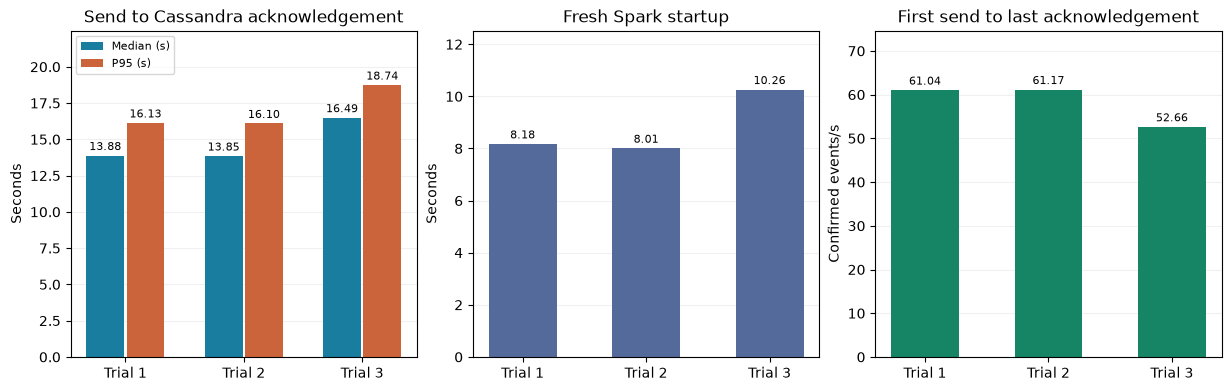

**Interpretation.** Median latency ranged from 13.85 to 16.49 s. P95 ranged from 16.10 to 18.74 s. Fresh Spark startup to its first batch varied from 8.01 to 10.26 s. Earlier events waited longer for the shared acknowledgement because publication took about five seconds. The percentiles describe this finite replay pattern rather than steady-state stream processing.

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(12.2, 3.8), layout="constrained")
x = np.arange(len(trials))
for offset, column, color in [(-0.17, "Median (s)", "#197DA0"), (0.17, "P95 (s)", "#CC643B")]:
    bars = axes[0].bar(x + offset, trials[column], width=0.32, label=column, color=color)
    axes[0].bar_label(bars, fmt="%.2f", fontsize=8, padding=2)
axes[0].set(title="Send to Cassandra acknowledgement", ylabel="Seconds", ylim=(0, trials["P95 (s)"].max() * 1.2))
axes[0].legend(loc="upper left", fontsize=8)
for axis, column, color, ylabel, title in [
    (axes[1], "Launch to first batch (s)", "#546A9A", "Seconds", "Fresh Spark startup"),
    (axes[2], "Throughput (events/s)", "#168566", "Confirmed events/s", "First send to last acknowledgement"),
]:
    bars = axis.bar(x, trials[column], width=0.55, color=color)
    axis.bar_label(bars, fmt="%.2f", fontsize=8, padding=2)
    axis.set(title=title, ylabel=ylabel, ylim=(0, trials[column].max() * 1.22))
for axis in axes:
    axis.set_xticks(x, trials["Workload"])
    axis.grid(axis="y", alpha=0.18)
    axis.set_axisbelow(True)
plt.show()
display(Markdown(
    f"**Interpretation.** Median latency ranged from {trials['Median (s)'].min():.2f} to "
    f"{trials['Median (s)'].max():.2f} s. P95 ranged from {trials['P95 (s)'].min():.2f} to "
    f"{trials['P95 (s)'].max():.2f} s. Fresh Spark startup to its first batch varied from "
    f"{trials['Launch to first batch (s)'].min():.2f} to {trials['Launch to first batch (s)'].max():.2f} s. "
    "Earlier events waited longer for the shared acknowledgement because publication took about five seconds. "
    "The percentiles describe this finite replay pattern rather than steady-state stream processing."
))

## Record the viva rehearsal separately

Read the stopwatch evidence for starting the prepared Compose services and the single-record dashboard rehearsal. This run uses the presenter’s replay path, including explanation capture, and has its own timing boundary.

In [5]:
rehearsal = json.loads((figures / "streaming_viva_rehearsal.json").read_text())
display(pd.Series({
    "Prepared stack startup (s)": round(rehearsal["stack_startup_s"], 2),
    "Selected record": rehearsal["record_number"],
    "Run": rehearsal["run_id"],
    "Click to displayed prediction (s)": round(rehearsal["click_to_prediction_s"], 2),
    "Worker Spark process (s)": round(rehearsal["spark_job_s"], 2),
    "Attack score": round(rehearsal["attack_score"], 8),
    "Predicted class": rehearsal["prediction"],
}, name="Observed").to_frame())
display(Markdown(
    f"**Interpretation.** {rehearsal['boundary']} The browser displayed the selected result, "
    "the checked explanation and the saved model comparison. The Cassandra query returned the same run and event. "
    "A separate laptop should verify its own startup and replay times using the same image, model and dataset."
))

,Observed
Prepared stack startup (s),34.42
Selected record,1
Run,selected.323915e92d8043bca91ecb442d0118e7
Click to displayed prediction (s),20.77
Worker Spark process (s),13.35
Attack score,0.999969
Predicted class,Suspected attack


**Interpretation.** Stopped service containers, existing images and Cassandra volume, Docker daemon already running; command entry to Compose readiness. The browser displayed the selected result, the checked explanation and the saved model comparison. The Cassandra query returned the same run and event. A separate laptop should verify its own startup and replay times using the same image, model and dataset.